# 🤗 Clasificación de reseñas de Olist con Transformers (Hugging Face)

**Objetivo:** clasificar automáticamente el **sentimiento** de las reseñas escritas por los clientes de Olist (portugués de Brasil) usando una **red neuronal tipo Transformer** de Hugging Face, y compararla con un modelo clásico.

**Pregunta:** ¿puede un modelo leer el comentario de un cliente y decir si es *negativo* o *positivo*?

> ⚠️ **Qué se ejecutó y qué no:** las celdas de datos y la **línea base clásica** (TF-IDF + regresión logística) ya traen sus salidas. Las celdas de **Hugging Face (🤗) NO se ejecutaron** aquí porque necesitan GPU e internet: ejecútenlas en **Google Colab** (instrucciones abajo). Por eso este notebook **no trae métricas del transformer**; las obtendrán ustedes al correrlo.

## ▶️ Cómo ejecutarlo en Google Colab (≈5 pasos)
1. Abrir este notebook en [colab.research.google.com](https://colab.research.google.com) (*Archivo → Subir cuaderno*).
2. **Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)**.
3. Subir `olist_order_reviews_dataset.csv` (icono de carpeta de la izquierda → arrastrar el archivo, o usar la celda de subida).
4. Ejecutar todo en orden. **Recomendado:** la primera vez poner `SAMPLE_SIZE = 5000` para comprobar que todo funciona en pocos minutos; luego `None` para usar todos los datos.
5. Al final se guarda el modelo en la carpeta `bertimbau-olist-final/`.

## 🧭 Modelo recomendado

| Modelo (Hugging Face) | Tamaño aprox. | Ventaja | Cuándo usarlo |
|---|---|---|---|
| **`neuralmind/bert-base-portuguese-cased`** (BERTimbau base) ⭐ | ≈110 M parámetros | Preentrenado con texto en **portugués de Brasil**; tamaño razonable para una GPU T4 de Colab | **Recomendado**: el idioma coincide con Olist y es el estándar para portugués |
| `neuralmind/bert-large-portuguese-cased` (BERTimbau large) | ≈335 M | Suele rendir algo más, pero es más lento y consume más memoria | Si el base se queda corto y hay GPU potente |
| `xlm-roberta-base` | ≈270 M | Multilingüe, muy robusto | Si quieren un solo modelo para varios idiomas |
| `distilbert-base-multilingual-cased` | ≈135 M | Más ligero y rápido | Si hay poca GPU o necesitan inferencia veloz |
| `cardiffnlp/twitter-xlm-roberta-base-sentiment` | ≈280 M | Ya entrenado para sentimiento (3 clases, multilingüe, sobre tweets) | Para probar **sin entrenar** (*zero-shot*) como referencia |

**Recomendación:** hacer *fine-tuning* de **BERTimbau base**. Los comentarios de Olist son **muy cortos** (el 99% tiene 37 palabras o menos), así que el entrenamiento es ligero. Para cambiar de modelo basta con modificar `MODEL_NAME` en la celda de configuración.

## 0. Configuración

In [ ]:
# Solo Colab: instalar dependencias (torch ya viene instalado)
!pip install -q "transformers>=4.46,<5" "accelerate>=0.34" scikit-learn

In [ ]:
# Solo Colab: subir el CSV si no lo arrastraron a la carpeta de archivos
from google.colab import files
files.upload()        # seleccionar olist_order_reviews_dataset.csv

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)

# ---------------- Parámetros del experimento ----------------
SEED = 42
NUM_CLASSES = 2        # 2 = negativo/positivo (recomendado para empezar) | 3 = negativo/neutral/positivo
SAMPLE_SIZE = None     # p. ej. 5000 para una prueba rápida; None = todos los datos
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"

# Busca el CSV en Colab, en la carpeta actual o en el repo del proyecto
CANDIDATES = [Path("olist_order_reviews_dataset.csv"), Path("/content/olist_order_reviews_dataset.csv"),
              Path("../data/raw/olist_order_reviews_dataset.csv"), Path("data/raw/olist_order_reviews_dataset.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
assert DATA_PATH is not None, "No se encontró olist_order_reviews_dataset.csv: súbanlo a Colab o al repo."
print("Datos:", DATA_PATH, "| clases:", NUM_CLASSES, "| modelo:", MODEL_NAME)

Datos: ../data/raw/olist_order_reviews_dataset.csv | clases: 2 | modelo: neuralmind/bert-base-portuguese-cased


## 1. Datos: reseñas con texto

Solo usamos la tabla `olist_order_reviews_dataset.csv`. Los clientes dejan una **nota de 1 a 5** y, opcionalmente, un **comentario**. Solo las reseñas con comentario sirven para clasificar texto.

Limpieza mínima:
- Quitar reseñas sin comentario y normalizar espacios.
- **Eliminar textos duplicados** (hay muchos "Muito bom", "Ótimo"...). Si el mismo texto cae en entrenamiento *y* en prueba, la evaluación sale inflada (**fuga de datos**).

In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.dropna(subset=["review_comment_message"]).copy()
df["text"] = df["review_comment_message"].str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["text"].str.len() > 0]
n_con_texto = len(df)
df = df.drop_duplicates("text")
print(f"Reseñas totales: {len(raw):,} | con comentario: {n_con_texto:,} ({100 * n_con_texto / len(raw):.1f}%)")
print(f"Textos duplicados eliminados: {n_con_texto - len(df):,} | reseñas únicas con texto: {len(df):,}")
df[["review_score", "text"]].sample(6, random_state=SEED)

Reseñas totales: 99,224 | con comentario: 40,950 (41.3%)
Textos duplicados eliminados: 5,335 | reseñas únicas con texto: 35,615


,review_score,text
75621,1,"Produto entregue conforme anuncio, porém com vários defeitos ( quebrado, trincado, peça solta ), e até mom..."
5503,1,"PRODUTO NÃO CHEGOU,E JÁ PASSOU O PRAZO DE ENTREGA"
49315,5,confio no baratheon
46671,5,"Muito bom de alta qualidade, superou minhas expectativas"
79776,3,"Tudo funcionando, mas percebi alguns arranhões no corpo da máquina. Nada que influencie o uso, mas pelo va..."
68171,5,entrega rapida produto muito bem embalado e sem avarias


Palabras -> mediana: 10 | p95: 33 | máximo: 45


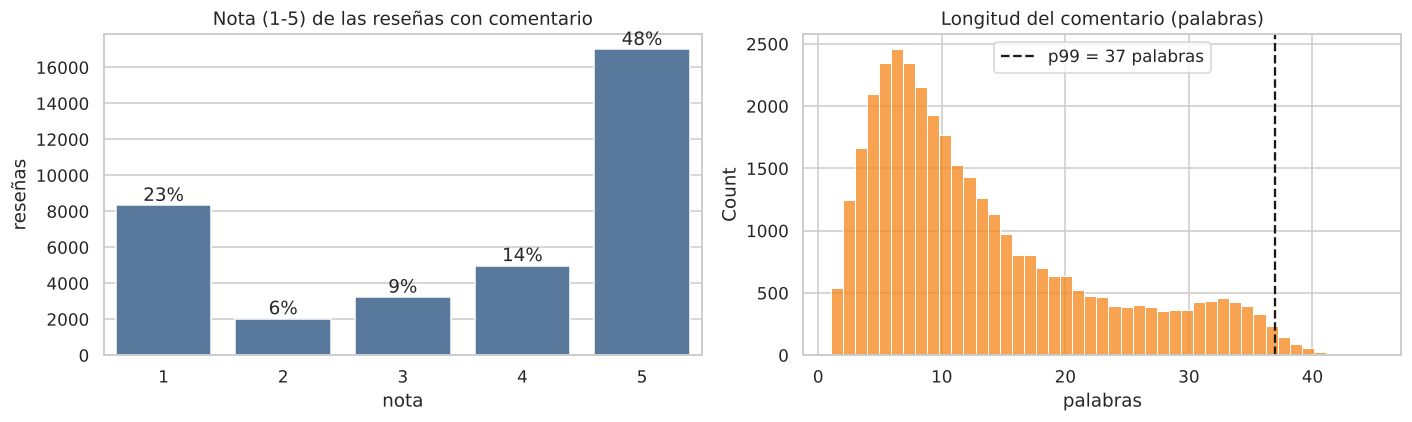

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sc = df["review_score"].value_counts().sort_index()
sns.barplot(x=sc.index, y=sc.values, ax=ax[0], color="#4c78a8")
ax[0].set_title("Nota (1-5) de las reseñas con comentario"); ax[0].set_xlabel("nota"); ax[0].set_ylabel("reseñas")
for i, v in enumerate(sc.values): ax[0].text(i, v, f"{100 * v / sc.sum():.0f}%", ha="center", va="bottom")
words = df["text"].str.split().str.len()
sns.histplot(words, bins=45, ax=ax[1], color="#f58518"); ax[1].axvline(np.percentile(words, 99), color="k", ls="--", label=f"p99 = {np.percentile(words, 99):.0f} palabras")
ax[1].set_title("Longitud del comentario (palabras)"); ax[1].set_xlabel("palabras"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Palabras -> mediana:", int(words.median()), "| p95:", int(np.percentile(words, 95)), "| máximo:", int(words.max()))

**Lectura:** la nota está **desbalanceada** (casi la mitad, ≈48%, son 5 estrellas) y los comentarios son **muy cortos** (mediana de 10 palabras). Eso permite usar secuencias cortas (rápido) y obliga a medir con **macro-F1** (promedio de F1 por clase) y no solo con *accuracy*.

## 2. Etiquetas: de la nota al sentimiento
| Nota | 2 clases (recomendado) | 3 clases |
|---|---|---|
| 1-2 | negativo | negativo |
| 3 | *(se descarta: ambigua)* | neutral |
| 4-5 | positivo | positivo |

Se recomienda **empezar con 2 clases** (más claro y estable). **3 clases** es el reto interesante: la clase *neutral* es difícil incluso para personas.

In [4]:
if NUM_CLASSES == 2:
    LABELS, LABEL_NAMES = {1: 0, 2: 0, 4: 1, 5: 1}, ["negativo", "positivo"]
else:
    LABELS, LABEL_NAMES = {1: 0, 2: 0, 3: 1, 4: 2, 5: 2}, ["negativo", "neutral", "positivo"]
df["label"] = df["review_score"].map(LABELS)
df = df.dropna(subset=["label"]).astype({"label": int})
if SAMPLE_SIZE:
    df = df.sample(min(SAMPLE_SIZE, len(df)), random_state=SEED)

from sklearn.model_selection import train_test_split
train_df, tmp = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.5, stratify=tmp["label"], random_state=SEED)
print(f"entrenamiento: {len(train_df):,} | validación: {len(val_df):,} | prueba: {len(test_df):,}")
pd.DataFrame({"clase": LABEL_NAMES, "% en entrenamiento": (train_df["label"].value_counts(normalize=True).sort_index() * 100).round(1).values})

entrenamiento: 25,900 | validación: 3,238 | prueba: 3,238


,clase,% en entrenamiento
0,negativo,32.1
1,positivo,67.9


## 3. Línea base clásica: TF-IDF + regresión logística

Antes de usar un transformer conviene tener una **referencia sencilla**. Si el transformer no la supera claramente, no vale la pena su costo. TF-IDF convierte cada comentario en un vector según las palabras (y pares de palabras) que contiene, y la regresión logística clasifica.

              precision    recall  f1-score   support

    negativo      0.866     0.934     0.898      1038
    positivo      0.967     0.932     0.949      2200

    accuracy                          0.932      3238
   macro avg      0.917     0.933     0.924      3238
weighted avg      0.935     0.932     0.933      3238

LÍNEA BASE  ->  accuracy 0.932 | macro-F1 0.924


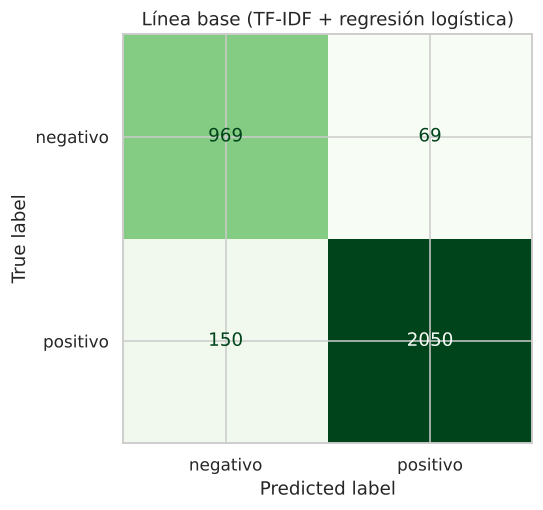

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
base = LogisticRegression(max_iter=2000, class_weight="balanced", C=3).fit(vec.fit_transform(train_df["text"]), train_df["label"])
pred_base = base.predict(vec.transform(test_df["text"]))
baseline_f1 = f1_score(test_df["label"], pred_base, average="macro")
print(classification_report(test_df["label"], pred_base, target_names=LABEL_NAMES, digits=3))
print(f"LÍNEA BASE  ->  accuracy {accuracy_score(test_df['label'], pred_base):.3f} | macro-F1 {baseline_f1:.3f}")

ConfusionMatrixDisplay.from_predictions(test_df["label"], pred_base, display_labels=LABEL_NAMES, cmap="Greens", colorbar=False)
plt.title("Línea base (TF-IDF + regresión logística)"); plt.tight_layout(); plt.show()

**Lectura:** con 2 clases la línea base ya es fuerte (macro-F1 ≈ 0.9). Con 3 clases (`NUM_CLASSES = 3`) cae a ≈ 0.66 y la clase *neutral* casi no se detecta (F1 ≈ 0.3): ahí es donde un transformer, que entiende el contexto (negaciones como "*não* recomendo", contrastes como "chegou rápido **mas** quebrado"), tiene más margen para mejorar. Si con 2 clases el transformer mejora poco, **el modelo clásico es suficiente**: es una conclusión válida y honesta.

---
# 🤗 Parte Hugging Face (ejecutar en Colab con GPU)

In [ ]:
import torch
from torch.utils.data import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          EarlyStoppingCallback, Trainer, TrainingArguments, pipeline, set_seed)

set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "SIN GPU: activa una en Entorno de ejecución → Cambiar tipo")

## 4. Tokenización

Un transformer no lee palabras sino **tokens** (trozos de palabra, *WordPiece*). El **tokenizador** del modelo convierte cada comentario en una lista de números y añade los tokens especiales `[CLS]` (inicio, de donde sale la clasificación) y `[SEP]` (fin).

`MAX_LEN` es la longitud máxima en tokens: más larga = más memoria y tiempo; más corta = se recorta texto. Como los comentarios son cortos, lo **calculamos con los datos**: el percentil 99 de la longitud en tokens, redondeado a múltiplo de 8 (más eficiente en GPU).

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
muestra = train_df["text"].sample(min(5000, len(train_df)), random_state=SEED)
lens = [len(tokenizer(t)["input_ids"]) for t in muestra]
MAX_LEN = int(np.ceil(np.percentile(lens, 99) / 8) * 8)
print("Longitud en tokens -> mediana:", int(np.median(lens)), "| p95:", int(np.percentile(lens, 95)), "| p99:", int(np.percentile(lens, 99)), "| máx:", max(lens))
print("MAX_LEN =", MAX_LEN)
print("\nEjemplo:", train_df["text"].iloc[0])
print(tokenizer.convert_ids_to_tokens(tokenizer(train_df["text"].iloc[0])["input_ids"]))

In [ ]:
class ReviewsDataset(Dataset):
    # Tokeniza sin padding; el DataCollator rellena cada lote hasta su texto más largo (más eficiente)
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN)
        self.labels = list(labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        return item

train_ds, val_ds, test_ds = (ReviewsDataset(d["text"], d["label"]) for d in (train_df, val_df, test_df))
collator = DataCollatorWithPadding(tokenizer)
print("Ejemplos -> entrenamiento:", len(train_ds), "| validación:", len(val_ds), "| prueba:", len(test_ds))

## 5. El modelo: BERT con una "cabeza" de clasificación

`AutoModelForSequenceClassification` carga **BERTimbau ya preentrenado** y le añade encima una capa final de clasificación **que empieza con pesos aleatorios**. Al hacer *fine-tuning* se ajusta todo el modelo (suavemente) para nuestra tarea.

Flujo de una reseña:
`texto → tokens → embeddings (768) → 12 capas Transformer (atención + red feed-forward) → vector del token [CLS] (768) → capa lineal 768 → N neuronas → softmax → probabilidad de cada clase`

*Cantidad de neuronas de salida = número de clases* (2 ó 3).

In [ ]:
id2label = {i: n for i, n in enumerate(LABEL_NAMES)}
label2id = {n: i for i, n in id2label.items()}
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_CLASSES, id2label=id2label, label2id=label2id)
n_params = sum(p.numel() for p in model.parameters())
print(f"Capas Transformer: {model.config.num_hidden_layers} | tamaño oculto: {model.config.hidden_size} | cabezas de atención: {model.config.num_attention_heads}")
print(f"Parámetros totales: {n_params / 1e6:.0f} M | neuronas de salida: {model.config.num_labels}")
print(model.classifier)

## 6. Entrenamiento (*fine-tuning*)

Valores estándar recomendados para ajustar BERT (Devlin et al., 2019): **2–4 épocas**, **learning rate 2e-5 a 5e-5**, lote 16–32.

| Hiperparámetro | Valor | Por qué |
|---|---|---|
| Épocas | **3** (máx.) + parada temprana | Con más épocas el modelo empieza a memorizar; la parada temprana corta si la validación no mejora |
| Learning rate | **2e-5** | Pequeño: ajusta sin "olvidar" lo aprendido en el preentrenamiento |
| Lote | **32** | Cabe bien en una T4 con textos cortos |
| Warmup | 10% | Sube el learning rate gradualmente al inicio: entrenamiento más estable |
| Weight decay | 0.01 | Regularización suave |
| Precisión mixta (fp16) | sí, si hay GPU | Más rápido y menos memoria |
| Métrica para elegir el mejor | **macro-F1** de validación | Los datos están desbalanceados |

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    return {"accuracy": accuracy_score(labels, preds), "f1_macro": f1_score(labels, preds, average="macro")}

args = TrainingArguments(
    output_dir="bertimbau-olist", num_train_epochs=3, learning_rate=2e-5, weight_decay=0.01, warmup_ratio=0.1,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1_macro",
    save_total_limit=1, fp16=torch.cuda.is_available(), seed=SEED, report_to="none", logging_steps=50)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collator,
                  processing_class=tokenizer, compute_metrics=compute_metrics,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=1)])
trainer.train()

## 7. Evaluación en el conjunto de prueba (datos que el modelo nunca vio)

In [ ]:
out = trainer.predict(test_ds)
pred_bert = out.predictions.argmax(axis=-1)
bert_f1 = f1_score(test_df["label"], pred_bert, average="macro")
print(classification_report(test_df["label"], pred_bert, target_names=LABEL_NAMES, digits=3))
print(f"BERTimbau   ->  accuracy {accuracy_score(test_df['label'], pred_bert):.3f} | macro-F1 {bert_f1:.3f}")
print(f"Línea base  ->  macro-F1 {baseline_f1:.3f}   (mejora del transformer: {bert_f1 - baseline_f1:+.3f})")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(test_df["label"], pred_base, display_labels=LABEL_NAMES, cmap="Greens", colorbar=False, ax=ax[0]); ax[0].set_title("Línea base")
ConfusionMatrixDisplay.from_predictions(test_df["label"], pred_bert, display_labels=LABEL_NAMES, cmap="Blues", colorbar=False, ax=ax[1]); ax[1].set_title("BERTimbau")
plt.tight_layout(); plt.show()

### Cómo interpretar el resultado
- **macro-F1** es la métrica principal. Si BERTimbau supera a la línea base por una diferencia pequeña en 2 clases, es normal: la tarea ya es fácil. La diferencia suele crecer en 3 clases y en reseñas con negación o contraste.
- Revisen la **matriz de confusión**: ¿los errores son entre clases vecinas (neutral ↔ positivo)? Es lo esperable.
- Como nota y comentario a veces no coinciden (alguien pone 5 estrellas pero escribe una queja), parte del "error" es **ruido en las etiquetas**, no del modelo.

In [ ]:
# Análisis de errores: ¿qué reseñas se equivocan más?
err = test_df.assign(predicho=pd.Series(pred_bert, index=test_df.index).map(id2label), real=test_df["label"].map(id2label))
err = err[err["real"] != err["predicho"]]
print(f"Errores: {len(err)} de {len(test_df)} ({100 * len(err) / len(test_df):.1f}%)")
err[["review_score", "real", "predicho", "text"]].sample(min(10, len(err)), random_state=SEED)

## 8. Guardar el modelo y usarlo con reseñas nuevas

In [ ]:
SAVE_DIR = "bertimbau-olist-final"
trainer.save_model(SAVE_DIR); tokenizer.save_pretrained(SAVE_DIR)

clf = pipeline("text-classification", model=SAVE_DIR, tokenizer=SAVE_DIR, device=0 if torch.cuda.is_available() else -1)
ejemplos = ["Chegou antes do prazo, produto excelente, recomendo!",
            "Não recebi o produto e ninguém responde meus e-mails.",
            "O produto chegou, mas veio com a caixa quebrada.",
            "Produto ok, nada de especial."]
for t, r in zip(ejemplos, clf(ejemplos)):
    print(f"{r['label']:>9} ({r['score']:.2f})  <-  {t}")

# 📘 Explicación sencilla de la red neuronal

## ¿Qué es un Transformer?
Es una red neuronal que lee **todo el texto a la vez** y, mediante un mecanismo de **atención**, decide qué palabras son importantes para entender cada otra palabra (por ejemplo, que "*não*" cambia el sentido de "*recomendo*"). **BERT** es un Transformer que se **preentrena** leyendo enormes cantidades de texto (aprende el idioma) y luego se **ajusta** (*fine-tuning*) con pocos datos para una tarea concreta. **BERTimbau** es BERT preentrenado en portugués de Brasil.

## Arquitectura de este clasificador
| Parte | Detalle |
|---|---|
| **Entrada** | Hasta `MAX_LEN` tokens por reseña; cada token se convierte en un vector de **768** números (*embedding*) |
| **Cuerpo** | **12** capas Transformer idénticas: atención multi-cabeza (12 cabezas) + red feed-forward de 3072 neuronas, con normalización y conexiones residuales (≈110 M de parámetros) |
| **Resumen del texto** | El vector final del token especial **`[CLS]`** (768 valores) resume toda la reseña |
| **Cabeza de clasificación** | Capa lineal **768 → N** |
| **Salida** | **N neuronas = N clases** (2 si es negativo/positivo, 3 si añade neutral) |

## Funciones de activación y de pérdida
- **GELU** en las capas feed-forward internas de BERT: parecida a ReLU pero suave; funciona mejor en Transformers.
- **Softmax** en la salida: convierte las N neuronas en probabilidades que suman 1 (p. ej., 0.93 positivo / 0.07 negativo).
- **Entropía cruzada** como pérdida: penaliza más cuanto más baja es la probabilidad asignada a la clase correcta.
- **Optimizador AdamW** con *warmup* y decaimiento lineal del learning rate.

## Épocas y por qué
**3 épocas como máximo con parada temprana.** El *fine-tuning* de BERT converge rápido porque el modelo ya sabe el idioma; con más épocas tiende a sobreajustar. La parada temprana vigila el macro-F1 de validación y conserva los mejores pesos.

## Parámetros que conviene probar después
`NUM_CLASSES = 3`, `MODEL_NAME` (otros modelos de la tabla), `learning_rate` (2e-5 / 3e-5 / 5e-5), lote 16 vs 32, pérdida con pesos por clase si el desbalance perjudica a *negativo*.

## Limitaciones
- Las etiquetas vienen de la **nota** (1–5), no de un etiquetado manual del sentimiento: hay ruido.
- Solo ≈41% de las reseñas tiene comentario; el modelo no ve al resto de clientes.
- Con 2 clases la línea base clásica ya es muy competitiva; el valor del transformer se aprecia más en casos difíciles.
- Los resultados dependen de la semilla y de la versión de las librerías; reporten al menos 2–3 ejecuciones si van a comparar modelos.

## Cómo conectarlo con el proyecto de segmentación
Una vez entrenado, pueden **predecir el sentimiento de cada reseña** y añadirlo como variable del cliente (p. ej., % de reseñas negativas) para segmentar a quienes tuvieron mala experiencia (ver los tiempos de entrega del notebook 02), o crear una pestaña en la app de Streamlit que reciba un comentario y devuelva su sentimiento.

**Referencias:** Devlin et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. · Souza, Nogueira & Lotufo (2020). *BERTimbau: pretrained BERT models for Brazilian Portuguese*. · Olist. (2018). *Brazilian E-Commerce Public Dataset by Olist* [Conjunto de datos]. Kaggle.